<a href="https://colab.research.google.com/github/mawardi-IF/ilp-hazard-kelompok-2/blob/main/war_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ILP Simulator - Implementasi WAR (Write After Read)

Jalankan sel di bawah (Runtime → Run all). Dependency graph akan tampil di bawah output dan tersimpan sebagai PNG di panel Files.



************************************************************
         SIMULATOR UNTUK MELIHAT ANTREAN KERJA (WAR)
************************************************************

Daftar Tugas:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R2 = R7 + R8
I4: R5 = R9 + R10
I5: R9 = R11 + R12
I6: R13 = R14 + R15

DAFTAR TUGAS YANG HARUS SALING MENUNGGU
* I3 harus menunggu I1 karena sama-sama memakai Register R2
* I4 harus menunggu I2 karena sama-sama memakai Register R5
* I5 harus menunggu I4 karena sama-sama memakai Register R9

CARA LAMBAT: DIKERJAKAN SATU PER SATU
Detik ke-1: Menjalankan I1 (R1 = R2 + R3)
Detik ke-2: Menjalankan I2 (R4 = R5 + R6)
Detik ke-3: Menjalankan I3 (R2 = R7 + R8)
Detik ke-4: Menjalankan I4 (R5 = R9 + R10)
Detik ke-5: Menjalankan I5 (R9 = R11 + R12)
Detik ke-6: Menjalankan I6 (R13 = R14 + R15)

Total Waktu Cara Lambat: 6 detik

CARA CEPAT: DIKERJAKAN BERSAMAAN (ILP)

Detik ke-1:
  -> I1 sedang berjalan: R1 = R2 + R3
  -> I2 sedang berjalan: R4 = R5 + R6
  -> I6 sedang berj

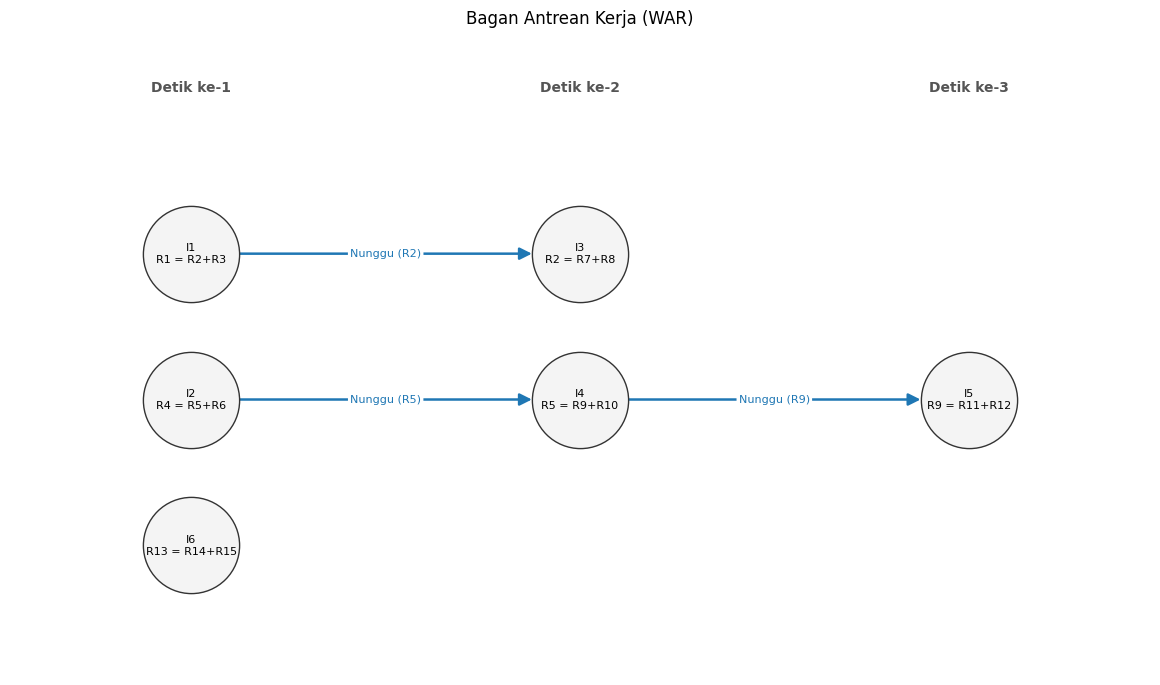

Gambar bagan berhasil disimpan dengan nama: bagan_antrean_war.png


In [5]:
# =================================================================
# SIMULATOR ILP - PENJELASAN SEDERHANA DEPENDENSI WAR
# =================================================================
# Apa itu WAR (Write After Read)?
#   WAR terjadi ketika ada instruksi baru yang ingin MENULIS (mengubah)
#   nilai suatu register, padahal register tersebut masih harus
#   DIBACA oleh instruksi sebelumnya.
#
#   Instruksi baru harus MENUNGGU sampai instruksi lama selesai
#   membaca register tersebut. Jika tidak ditunggu, instruksi lama
#   akan membaca data baru yang salah.
#
#   Contoh nyata:
#     - Ani sedang membaca buku fisika (Read R2)
#     - Budi ingin menulis coretan di buku fisika yang sama (Write R2)
#     - Budi harus menunggu Ani selesai membaca buku tersebut.
# =================================================================

from dataclasses import dataclass
import matplotlib.pyplot as plt
import networkx as nx

HAZARD = "WAR"
HAZARD_FULL = "WAR (Menulis Setelah Membaca)"
EDGE_COLOR = "#1f77b4"  # Biru penanda antrean

@dataclass
class Instruction:
    name: str           # Nama langkah (I1, I2, ...)
    destination: str    # Tempat menulis hasil (Register Tujuan)
    sources: list       # Bahan yang dibaca (Register Sumber)

# -------------------------------------------------
# Daftar Instruksi yang akan dijalankan
# -------------------------------------------------
instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),     # Membaca R2
    Instruction("I2", "R4", ["R5", "R6"]),     # Membaca R5
    Instruction("I3", "R2", ["R7", "R8"]),     # Menulis ke R2 (Harus nunggu I1 selesai membaca)
    Instruction("I4", "R5", ["R9", "R10"]),    # Menulis ke R5 (Harus nunggu I2 selesai membaca)
    Instruction("I5", "R9", ["R11", "R12"]),   # Menulis ke R9 (Harus nunggu I4 selesai membaca)
    Instruction("I6", "R13", ["R14", "R15"]),  # Bebas, bisa langsung jalan
]

# -------------------------------------------------
# Cek Hubungan Antrean (WAR)
# -------------------------------------------------
def dependency_register(inst1, inst2):
    # Cek apakah inst2 mencoba menulis ke register yang sedang dibaca inst1
    if inst2.destination in inst1.sources:
        return inst2.destination
    return None

def has_dependency(inst1, inst2):
    return dependency_register(inst1, inst2) is not None

# -------------------------------------------------
# Cara Lambat: Satu-satu (Sequential)
# -------------------------------------------------
def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("CARA LAMBAT: DIKERJAKAN SATU PER SATU")
    print("=" * 50)

    cycle = 0
    for instruction in instructions:
        cycle += 1
        print(f"Detik ke-{cycle}: Menjalankan {instruction.name} ({instruction.destination} = {' + '.join(instruction.sources)})")

    print(f"\nTotal Waktu Cara Lambat: {cycle} detik")
    return cycle

# -------------------------------------------------
# Cara Cepat: Bersamaan (ILP Parallel)
# -------------------------------------------------
def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("CARA CEPAT: DIKERJAKAN BERSAMAAN (ILP)")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()
    cycle = 0

    while remaining:
        cycle += 1
        current_cycle = []

        for instruction in remaining:
            # Boleh jalan jika semua instruksi sebelumnya yang butuh membaca
            # register tujuan ini sudah selesai membaca.
            boleh_jalan = True
            for previous in instructions:
                if previous.name == instruction.name:
                    break
                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        boleh_jalan = False
                        break

            if boleh_jalan:
                current_cycle.append(instruction)

        print(f"\nDetik ke-{cycle}:")
        for instruction in current_cycle:
            print(f"  -> {instruction.name} sedang berjalan: {instruction.destination} = {' + '.join(instruction.sources)}")

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal Waktu Cara Cepat: {cycle} detik")
    return cycle

# -------------------------------------------------
# Tampilkan Analisis Hubungan Antrean
# -------------------------------------------------
def show_dependencies(instructions):
    print("\n" + "=" * 50)
    print("DAFTAR TUGAS YANG HARUS SALING MENUNGGU")
    print("=" * 50)

    found = False
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            register = dependency_register(instructions[i], instructions[j])
            if register:
                print(f"* {instructions[j].name} harus menunggu {instructions[i].name} karena sama-sama memakai Register {register}")
                found = True
    if not found:
        print("Semua tugas bebas dijalankan kapan saja tanpa antre.")

# -------------------------------------------------
# Membuat Gambar Bagan Hubungan
# -------------------------------------------------
def compute_ilp_cycles(instructions):
    cycle_of = {}
    for j, inst in enumerate(instructions):
        cycle_of[inst.name] = 1
        for prev in instructions[:j]:
            if has_dependency(prev, inst):
                cycle_of[inst.name] = max(cycle_of[inst.name], cycle_of[prev.name] + 1)
    return cycle_of

def draw_dependency_graph(instructions, filename="bagan_antrean_war.png"):
    G = nx.DiGraph()
    for inst in instructions:
        G.add_node(inst.name, label=f"{inst.name}\n{inst.destination} = {'+'.join(inst.sources)}")

    edge_labels = {}
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            register = dependency_register(instructions[i], instructions[j])
            if register:
                edge = (instructions[i].name, instructions[j].name)
                G.add_edge(*edge)
                edge_labels[edge] = f"Nunggu ({register})"

    cycle_of = compute_ilp_cycles(instructions)
    n_cycles = max(cycle_of.values())
    pos = {}
    for c in range(1, n_cycles + 1):
        members = [inst.name for inst in instructions if cycle_of[inst.name] == c]
        wanted = []
        for k, name in enumerate(members):
            preds = list(G.predecessors(name))
            y = sum(pos[p][1] for p in preds) / len(preds) if preds else -k * 1.8
            wanted.append((-y, k, name))
        wanted.sort()
        last_y = None
        for neg_y, _, name in wanted:
            y = -neg_y
            if last_y is not None and y > last_y - 1.8:
                y = last_y - 1.8
            pos[name] = (c * 3.0, y)
            last_y = y

    ys = [p[1] for p in pos.values()]
    height = max(ys) - min(ys)
    fig, ax = plt.subplots(figsize=(3.4 * n_cycles + 1.5, 0.95 * height + 3.2))

    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=4800, node_color="#f4f4f4", edgecolors="#333333")
    nx.draw_networkx_labels(G, pos, ax=ax, labels=nx.get_node_attributes(G, "label"), font_size=8)

    def blocked(u, v):
        (x1, y1), (x2, y2) = pos[u], pos[v]
        for n, (x, y) in pos.items():
            if n in (u, v) or not (min(x1, x2) < x < max(x1, x2)):
                continue
            t = (x - x1) / (x2 - x1)
            if abs(y1 + t * (y2 - y1) - y) < 0.9:
                return True
        return False

    straight = [e for e in G.edges if not blocked(*e)]
    curved = [e for e in G.edges if blocked(*e)]

    top = max(ys) + 2.0
    ax.set_xlim(1.6, n_cycles * 3.0 + 1.4)
    ax.set_ylim(min(ys) - 1.6, top + 0.6)
    plt.tight_layout()

    for edges, rad in [(straight, 0.0), (curved, -0.35)]:
        if not edges:
            continue
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color=EDGE_COLOR,
                               width=1.8, arrows=True, arrowsize=18,
                               node_size=4800, connectionstyle=f"arc3,rad={rad}")
        for u, v in edges:
            (x1, y1), (x2, y2) = ax.transData.transform([pos[u], pos[v]])
            mx = (x1 + x2) / 2 + 0.5 * rad * (y2 - y1)
            my = (y1 + y2) / 2 - 0.5 * rad * (x2 - x1)
            lx, ly = ax.transData.inverted().transform((mx, my))
            ax.text(lx, ly, edge_labels[(u, v)], fontsize=8, color=EDGE_COLOR,
                    ha="center", va="center", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"))

    for c in range(1, n_cycles + 1):
        ax.text(c * 3.0, top, f"Detik ke-{c}", ha="center", fontsize=10,
                fontweight="bold", color="#555555")

    ax.set_title("Bagan Antrean Kerja (WAR)", fontsize=12, pad=14)
    ax.axis("off")
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Gambar bagan berhasil disimpan dengan nama: {filename}")

# -------------------------------------------------
# Program Utama
# -------------------------------------------------
def main():
    print("\n")
    print("*" * 60)
    print("         SIMULATOR UNTUK MELIHAT ANTREAN KERJA (WAR)")
    print("*" * 60)

    print("\nDaftar Tugas:")
    for instruction in instructions:
        print(f"{instruction.name}: {instruction.destination} = {' + '.join(instruction.sources)}")

    show_dependencies(instructions)

    sequential_cycles = sequential_execution(instructions)
    parallel_cycles = parallel_execution(instructions)

    speedup = sequential_cycles / parallel_cycles
    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERBANDINGAN KECEPATAN")
    print("=" * 50)
    print(f"Waktu Cara Lambat : {sequential_cycles} detik")
    print(f"Waktu Cara Cepat  : {parallel_cycles} detik")
    print(f"Lebih Cepat       : {speedup:.2f}x lipat")
    print(f"Efisiensi Kerja   : {efficiency:.2f}%")

    print("\nKesimpulan Sederhana:")
    print(
        "Ada beberapa tugas yang harus mengantre agar datanya tidak tabrakan.\n"
        "Supaya tidak perlu mengantre, solusinya adalah mengganti nama tempat simpan\n"
        "data (register renaming). Dengan begitu, pekerjaan selesai jauh lebih cepat!"
    )

    draw_dependency_graph(instructions)

if __name__ == "__main__":
    main()
